# 4. Model performance — Figure 4 plots

Grouped bootstrap: 2,000 metric draws and 1,000 draws for pointwise curve bands.

## Load predictions

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "mea_ml" / "io.py").is_file()
)
sys.path.insert(0, str(PROJECT_ROOT))

from mea_ml.plotting import save_png
import json
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)
from IPython.display import display

N_BOOTSTRAP = 2000
CURVE_BAND_BOOTSTRAP = 1000
CURVE_BAND_CI = 0.95

from mea_ml.io import ROOT as PROJECT_ROOT, load_ml_summary
EXPORT_ROOT = PROJECT_ROOT / "results"
ML_DIR = EXPORT_ROOT / "03_ml"
OUT_DIR = EXPORT_ROOT / "04_performance"
OUT_DIR.mkdir(parents=True, exist_ok=True)

FIG4_OUT_DIR = OUT_DIR / "figure4"
FIG4_OUT_DIR.mkdir(parents=True, exist_ok=True)

ml_summary = load_ml_summary()
RANDOM_STATE = int(ml_summary["random_state"])
BOOTSTRAP_SEED = RANDOM_STATE + 123
CURVE_BAND_SEED = RANDOM_STATE + 2024
main_results = pd.read_csv(ML_DIR / "model_results_main.csv")
oof_main = pd.read_csv(ML_DIR / "oof_predictions_main.csv")
oof_by_repeat = pd.read_csv(ML_DIR / "oof_predictions_by_repeat.csv")
N_REPEATS = ml_summary["n_repeats"]
OUTER_N_SPLITS = ml_summary["outer_n_splits"]

print("Loaded files successfully.")
print("Selected model from 03:", ml_summary["selected_model_name"])
print("Selected feature set from 03:", ml_summary["selected_feature_set"])


Loaded files successfully.
Selected model from 03: XGBoost
Selected feature set from 03: mean+delta


## Metrics and plot settings

In [2]:
oof_cols_main = {"model": "model_name", "feature_set": "feature_set", "y_true": "y_true",
                 "y_pred": "y_pred", "y_score": "y_proba", "group_id": "group_id", "fold_id": "outer_fold_id"}
oof_cols_repeat = oof_cols_main.copy()

def pooled_metrics(df: pd.DataFrame, cols: Dict[str, str]) -> Dict[str, float]:
    y_true = df[cols["y_true"]].astype(int).to_numpy()
    y_pred = df[cols["y_pred"]].astype(int).to_numpy()
    y_score = df[cols["y_score"]].astype(float).to_numpy()

    metrics = {
        "roc_auc": roc_auc_score(y_true, y_score),
        "pr_auc": average_precision_score(y_true, y_score),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
    }
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    metrics["specificity"] = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    return metrics

def bootstrap_groups(df: pd.DataFrame, cols: Dict[str, str], n_boot: int = 2000, seed: int = 123) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    groups = df[cols["group_id"]].astype(str).unique().tolist()
    rows = []
    for _ in range(n_boot):
        sampled = rng.choice(groups, size=len(groups), replace=True)
        boot = pd.concat(
            [df[df[cols["group_id"]].astype(str) == g] for g in sampled],
            axis=0,
            ignore_index=True,
        )
        if boot[cols["y_true"]].astype(int).nunique() < 2:
            continue
        try:
            rows.append(pooled_metrics(boot, cols))
        except Exception:
            continue
    return pd.DataFrame(rows)

def ci_from_boot(boot_df: pd.DataFrame, metric: str, alpha: float = 0.95) -> Tuple[float, float]:
    lo = (1 - alpha) / 2
    hi = 1 - lo
    return float(boot_df[metric].quantile(lo)), float(boot_df[metric].quantile(hi))

def simplify_feature_set_label(fs: str) -> str:
    if fs == "mean+delta":
        return "Mean + Delta"
    if fs == "delta-only":
        return "Delta only"
    if fs == "mfr-only":
        return "MFR only"
    return str(fs)

FEATURE_SET_ORDER = ["mean+delta", "delta-only", "mfr-only"]

FEATURE_SET_EDGE_COLORS = {
    "mean+delta": "#E46358",
    "delta-only": "#3F7DCF",
    "mfr-only": "#9E9E9E",
}
FEATURE_SET_FILL_COLORS = {
    "mean+delta": "#F5A198",
    "delta-only": "#8DB8EC",
    "mfr-only": "#D9D9D9",
}
POOLED_CURVE_COLOR = "#1E4D8A"
POOLED_BAND_COLOR = "#C9DCF3"
FOLD_CURVE_COLOR = "#1E90FF"
REFERENCE_LINE_COLOR = "#000000"

METRIC_LABELS = {
    "roc_auc": "ROC AUC",
    "pr_auc": "PR AUC",
    "accuracy": "Accuracy",
}

def add_alpha_to_hex(hex_color: str, alpha: float = 0.30) -> Tuple[float, float, float, float]:
    hex_color = hex_color.lstrip("#")
    rgb = tuple(int(hex_color[i:i+2], 16) / 255 for i in (0, 2, 4))
    return (*rgb, alpha)

def sort_feature_sets(values: pd.Series) -> pd.Series:
    mapping = {fs: i for i, fs in enumerate(FEATURE_SET_ORDER)}
    return values.map(mapping).fillna(999)

def sorted_fold_ids(values: pd.Series) -> List[str]:
    raw = values.dropna().astype(str).unique().tolist()

    def fold_key(v: str):
        try:
            return (0, int(v))
        except Exception:
            return (1, v)

    return sorted(raw, key=fold_key)

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
    "legend.title_fontsize": 11,
    "figure.titlesize": 22,
    "axes.spines.top": True,
    "axes.spines.right": True,
})


## Selected model

In [3]:
selected_model = str(ml_summary["selected_model_name"])
selected_feature_set = str(ml_summary["selected_feature_set"])

print("Selected primary combination:", selected_model, "+", selected_feature_set)

main_results_sorted = main_results.sort_values(
    ["pooled_roc_auc", "pooled_pr_auc", "pooled_balanced_accuracy", "roc_auc_std"],
    ascending=[False, False, False, True],
).reset_index(drop=True)

display(main_results_sorted)

selected_table = (
    main_results[main_results["model_name"].astype(str) == selected_model]
    .sort_values("feature_set", key=sort_feature_sets)
    .reset_index(drop=True)
)
display(selected_table)

main_display = main_results_sorted.copy()
main_display["feature_set_display"] = main_display["feature_set"].map(simplify_feature_set_label)
main_display


Selected primary combination: XGBoost + mean+delta


,model_name,feature_set,roc_auc_mean,roc_auc_std,pooled_roc_auc,pooled_pr_auc,pooled_accuracy,pooled_balanced_accuracy,pooled_f1,pooled_precision,...,repeat_balanced_accuracy_mean,repeat_balanced_accuracy_std,repeat_f1_mean,repeat_f1_std,repeat_precision_mean,repeat_precision_std,repeat_recall_mean,repeat_recall_std,repeat_specificity_mean,repeat_specificity_std
0,XGBoost,mean+delta,0.884722,0.157437,0.909444,0.953164,0.855556,0.816667,0.896000,0.861538,...,0.813889,0.026788,0.885946,0.013001,0.867337,0.021323,0.905556,0.009623,0.722222,0.050918
1,Gradient Boosting,mean+delta,0.887963,0.138015,0.891667,0.936087,0.855556,0.833333,0.892562,0.885246,...,0.811111,0.039382,0.875516,0.020310,0.873449,0.031003,0.877778,0.009623,0.744444,0.069389
2,Random Forest,mean+delta,0.865278,0.167199,0.875000,0.913385,0.833333,0.791667,0.880000,0.846154,...,0.780556,0.038490,0.871763,0.020327,0.840679,0.028237,0.905556,0.019245,0.655556,0.069389
3,XGBoost,delta-only,0.870370,0.152838,0.872778,0.931704,0.800000,0.741667,0.859375,0.808824,...,0.766667,0.044096,0.871059,0.033860,0.825678,0.023615,0.922222,0.050918,0.611111,0.050918
4,Logistic Regression,delta-only,0.807407,0.145182,0.852222,0.933545,0.733333,0.700000,0.800000,0.800000,...,0.716667,0.036324,0.801004,0.043154,0.816639,0.023637,0.788889,0.078764,0.644444,0.069389
5,Logistic Regression,mean+delta,0.876852,0.170739,0.852222,0.923214,0.788889,0.766667,0.840336,0.847458,...,0.791667,0.036324,0.844919,0.021924,0.875294,0.029296,0.816667,0.016667,0.766667,0.057735
6,CatBoost,mean+delta,0.872222,0.169308,0.832778,0.875774,0.822222,0.775000,0.873016,0.833333,...,0.783333,0.014434,0.874361,0.019698,0.841033,0.004441,0.911111,0.041944,0.655556,0.019245
7,Gradient Boosting,delta-only,0.867130,0.159071,0.832222,0.842990,0.811111,0.750000,0.868217,0.811594,...,0.741667,0.041667,0.855818,0.013123,0.812304,0.033094,0.905556,0.025459,0.577778,0.101835
8,Random Forest,delta-only,0.846296,0.168677,0.809444,0.882035,0.766667,0.691667,0.839695,0.774648,...,0.705556,0.024056,0.843261,0.006177,0.785089,0.018084,0.911111,0.009623,0.500000,0.057735
9,SVM (RBF),delta-only,0.788889,0.141853,0.803889,0.875212,0.722222,0.691667,0.789916,0.796610,...,0.680556,0.055486,0.789695,0.043747,0.785164,0.034160,0.794444,0.053576,0.566667,0.057735


,model_name,feature_set,roc_auc_mean,roc_auc_std,pooled_roc_auc,pooled_pr_auc,pooled_accuracy,pooled_balanced_accuracy,pooled_f1,pooled_precision,...,repeat_balanced_accuracy_mean,repeat_balanced_accuracy_std,repeat_f1_mean,repeat_f1_std,repeat_precision_mean,repeat_precision_std,repeat_recall_mean,repeat_recall_std,repeat_specificity_mean,repeat_specificity_std
0,XGBoost,mean+delta,0.884722,0.157437,0.909444,0.953164,0.855556,0.816667,0.896000,0.861538,...,0.813889,0.026788,0.885946,0.013001,0.867337,0.021323,0.905556,0.009623,0.722222,0.050918
1,XGBoost,delta-only,0.870370,0.152838,0.872778,0.931704,0.800000,0.741667,0.859375,0.808824,...,0.766667,0.044096,0.871059,0.033860,0.825678,0.023615,0.922222,0.050918,0.611111,0.050918
2,XGBoost,mfr-only,0.527778,0.139508,0.495000,0.673589,0.666667,0.525000,0.791667,0.678571,...,0.494444,0.029266,0.767940,0.021725,0.663934,0.014540,0.911111,0.041944,0.077778,0.050918


,model_name,feature_set,roc_auc_mean,roc_auc_std,pooled_roc_auc,pooled_pr_auc,pooled_accuracy,pooled_balanced_accuracy,pooled_f1,pooled_precision,...,repeat_balanced_accuracy_std,repeat_f1_mean,repeat_f1_std,repeat_precision_mean,repeat_precision_std,repeat_recall_mean,repeat_recall_std,repeat_specificity_mean,repeat_specificity_std,feature_set_display
0,XGBoost,mean+delta,0.884722,0.157437,0.909444,0.953164,0.855556,0.816667,0.896000,0.861538,...,0.026788,0.885946,0.013001,0.867337,0.021323,0.905556,0.009623,0.722222,0.050918,Mean + Delta
1,Gradient Boosting,mean+delta,0.887963,0.138015,0.891667,0.936087,0.855556,0.833333,0.892562,0.885246,...,0.039382,0.875516,0.020310,0.873449,0.031003,0.877778,0.009623,0.744444,0.069389,Mean + Delta
2,Random Forest,mean+delta,0.865278,0.167199,0.875000,0.913385,0.833333,0.791667,0.880000,0.846154,...,0.038490,0.871763,0.020327,0.840679,0.028237,0.905556,0.019245,0.655556,0.069389,Mean + Delta
3,XGBoost,delta-only,0.870370,0.152838,0.872778,0.931704,0.800000,0.741667,0.859375,0.808824,...,0.044096,0.871059,0.033860,0.825678,0.023615,0.922222,0.050918,0.611111,0.050918,Delta only
4,Logistic Regression,delta-only,0.807407,0.145182,0.852222,0.933545,0.733333,0.700000,0.800000,0.800000,...,0.036324,0.801004,0.043154,0.816639,0.023637,0.788889,0.078764,0.644444,0.069389,Delta only
5,Logistic Regression,mean+delta,0.876852,0.170739,0.852222,0.923214,0.788889,0.766667,0.840336,0.847458,...,0.036324,0.844919,0.021924,0.875294,0.029296,0.816667,0.016667,0.766667,0.057735,Mean + Delta
6,CatBoost,mean+delta,0.872222,0.169308,0.832778,0.875774,0.822222,0.775000,0.873016,0.833333,...,0.014434,0.874361,0.019698,0.841033,0.004441,0.911111,0.041944,0.655556,0.019245,Mean + Delta
7,Gradient Boosting,delta-only,0.867130,0.159071,0.832222,0.842990,0.811111,0.750000,0.868217,0.811594,...,0.041667,0.855818,0.013123,0.812304,0.033094,0.905556,0.025459,0.577778,0.101835,Delta only
8,Random Forest,delta-only,0.846296,0.168677,0.809444,0.882035,0.766667,0.691667,0.839695,0.774648,...,0.024056,0.843261,0.006177,0.785089,0.018084,0.911111,0.009623,0.500000,0.057735,Delta only
9,SVM (RBF),delta-only,0.788889,0.141853,0.803889,0.875212,0.722222,0.691667,0.789916,0.796610,...,0.055486,0.789695,0.043747,0.785164,0.034160,0.794444,0.053576,0.566667,0.057735,Delta only


## Grouped bootstrap

In [4]:
sel_oof = oof_main[
    (oof_main[oof_cols_main["model"]].astype(str) == selected_model) &
    (oof_main[oof_cols_main["feature_set"]].astype(str) == selected_feature_set)
].copy()

if sel_oof.empty:
    raise RuntimeError("Selected primary combination not found in oof_predictions_main.csv")

sel_oof_by_repeat = oof_by_repeat[
    (oof_by_repeat[oof_cols_repeat["model"]].astype(str) == selected_model) &
    (oof_by_repeat[oof_cols_repeat["feature_set"]].astype(str) == selected_feature_set)
].copy()
if sel_oof_by_repeat[oof_cols_repeat["fold_id"]].isna().any():
    raise ValueError("Outer-fold curves require nonmissing fold IDs from the per-repeat OOF table.")
assert not sel_oof.duplicated("sample_index").any()
assert not sel_oof_by_repeat.duplicated(["repeat_id", "sample_index"]).any()
assert sel_oof_by_repeat.groupby("repeat_id").size().eq(len(sel_oof)).all()
assert sel_oof_by_repeat.groupby("sample_index").size().eq(N_REPEATS).all()
assert sel_oof_by_repeat.groupby(["repeat_id", oof_cols_repeat["group_id"]])[oof_cols_repeat["fold_id"]].nunique().eq(1).all()
mean_scores = sel_oof_by_repeat.groupby("sample_index")[oof_cols_repeat["y_score"]].mean().sort_index()
assert np.allclose(mean_scores, sel_oof.sort_values("sample_index")[oof_cols_main["y_score"]])
fold_curve_groups = sel_oof_by_repeat.groupby(["repeat_id", oof_cols_repeat["fold_id"]])
assert len(fold_curve_groups) == N_REPEATS * OUTER_N_SPLITS
fold_curve_audit = []
for (repeat_id, fold_id), fold_df in fold_curve_groups:
    group_labels = fold_df.groupby(oof_cols_repeat["group_id"])[oof_cols_repeat["y_true"]].first()
    assert len(fold_df) == 18 and len(group_labels) == 3 and group_labels.sum() == 2
    fold_curve_audit.append({
        "repeat_id": int(repeat_id), "outer_fold_id": int(fold_id),
        "n_well_pairs": len(fold_df), "n_groups": len(group_labels),
        **pooled_metrics(fold_df, oof_cols_repeat),
    })
fold_curve_audit_df = pd.DataFrame(fold_curve_audit)
fold_curve_audit_df.to_csv(FIG4_OUT_DIR / "figure4_outer_fold_curve_audit.csv", index=False)
print(f"Outer-fold curves: {len(fold_curve_groups)}; pooled curve: {len(sel_oof)} unique well pairs.")

pooled_sel = pooled_metrics(sel_oof, oof_cols_main)
pooled_sel_df = pd.DataFrame([pooled_sel])
display(pooled_sel_df)

boot_sel = bootstrap_groups(sel_oof, oof_cols_main, n_boot=N_BOOTSTRAP, seed=BOOTSTRAP_SEED)
ci_rows = []
for metric in ["roc_auc", "pr_auc", "balanced_accuracy", "accuracy", "f1", "precision", "recall", "specificity"]:
    lo, hi = ci_from_boot(boot_sel, metric)
    ci_rows.append({
        "metric": metric,
        "point_estimate": pooled_sel[metric],
        "ci_low": lo,
        "ci_high": hi,
    })
ci_df = pd.DataFrame(ci_rows)
display(ci_df)

selected_model_oof = oof_main[oof_main[oof_cols_main["model"]].astype(str) == selected_model].copy()

feature_set_rows = []
feature_set_ci_rows = []
feature_set_boot_dfs = []

for fs in FEATURE_SET_ORDER:
    sub = selected_model_oof[selected_model_oof[oof_cols_main["feature_set"]].astype(str) == fs].copy()
    if sub.empty:
        continue

    metrics = pooled_metrics(sub, oof_cols_main)
    metrics["model_name"] = selected_model
    metrics["feature_set"] = fs
    feature_set_rows.append(metrics)

    boot_sub = bootstrap_groups(sub, oof_cols_main, n_boot=N_BOOTSTRAP, seed=BOOTSTRAP_SEED)
    if boot_sub.empty:
        continue

    boot_sub["model_name"] = selected_model
    boot_sub["feature_set"] = fs
    feature_set_boot_dfs.append(boot_sub)

    for metric in ["roc_auc", "pr_auc", "accuracy"]:
        lo, hi = ci_from_boot(boot_sub, metric)
        feature_set_ci_rows.append({
            "model_name": selected_model,
            "feature_set": fs,
            "metric": metric,
            "point_estimate": metrics[metric],
            "ci_low": lo,
            "ci_high": hi,
        })

selected_model_feature_set_pooled = pd.DataFrame(feature_set_rows)
selected_model_feature_set_pooled = selected_model_feature_set_pooled.sort_values(
    "feature_set", key=sort_feature_sets
).reset_index(drop=True)

selected_model_feature_set_ci = pd.DataFrame(feature_set_ci_rows)
if not selected_model_feature_set_ci.empty:
    selected_model_feature_set_ci["feature_set_rank"] = selected_model_feature_set_ci["feature_set"].map(
        {fs: i for i, fs in enumerate(FEATURE_SET_ORDER)}
    )
    selected_model_feature_set_ci = (
        selected_model_feature_set_ci
        .sort_values(["feature_set_rank", "metric"])
        .drop(columns=["feature_set_rank"])
        .reset_index(drop=True)
    )

selected_model_feature_set_boot = pd.concat(feature_set_boot_dfs, axis=0, ignore_index=True)
selected_model_feature_set_boot_long = selected_model_feature_set_boot.melt(
    id_vars=["model_name", "feature_set"],
    value_vars=["roc_auc", "pr_auc", "accuracy"],
    var_name="metric",
    value_name="value",
)
selected_model_feature_set_boot_long["feature_set"] = pd.Categorical(
    selected_model_feature_set_boot_long["feature_set"],
    categories=FEATURE_SET_ORDER,
    ordered=True,
)
selected_model_feature_set_boot_long["metric"] = pd.Categorical(
    selected_model_feature_set_boot_long["metric"],
    categories=["roc_auc", "pr_auc", "accuracy"],
    ordered=True,
)
selected_model_feature_set_boot_long = selected_model_feature_set_boot_long.sort_values(
    ["metric", "feature_set"]
).reset_index(drop=True)

display(selected_model_feature_set_pooled)
display(selected_model_feature_set_ci.head())
display(selected_model_feature_set_boot_long.head())

pooled_sel_df.to_csv(FIG4_OUT_DIR / "figure4_selected_primary_pooled_metrics.csv", index=False)
ci_df.to_csv(FIG4_OUT_DIR / "figure4_selected_primary_group_bootstrap_ci.csv", index=False)
selected_model_feature_set_pooled.to_csv(FIG4_OUT_DIR / "figure4_selected_model_feature_set_pooled_metrics.csv", index=False)
selected_model_feature_set_ci.to_csv(FIG4_OUT_DIR / "figure4_selected_model_feature_set_bootstrap_ci.csv", index=False)
selected_model_feature_set_boot_long.to_csv(FIG4_OUT_DIR / "figure4_selected_model_feature_set_bootstrap_long.csv", index=False)

print("Saved Figure 4 quantitative tables to:", FIG4_OUT_DIR.relative_to(PROJECT_ROOT))


Outer-fold curves: 15; pooled curve: 90 unique well pairs.


,roc_auc,pr_auc,accuracy,balanced_accuracy,f1,precision,recall,specificity
0,0.909444,0.953164,0.855556,0.816667,0.896,0.861538,0.933333,0.7


,metric,point_estimate,ci_low,ci_high
0,roc_auc,0.909444,0.766815,0.993697
1,pr_auc,0.953164,0.850564,0.998298
2,balanced_accuracy,0.816667,0.638889,0.964286
3,accuracy,0.855556,0.732500,0.966667
4,f1,0.896000,0.761827,0.976797
5,precision,0.861538,0.666667,1.000000
6,recall,0.933333,0.833333,1.000000
7,specificity,0.700000,0.333333,1.000000


,roc_auc,pr_auc,accuracy,balanced_accuracy,f1,precision,recall,specificity,model_name,feature_set
0,0.909444,0.953164,0.855556,0.816667,0.896000,0.861538,0.933333,0.700000,XGBoost,mean+delta
1,0.872778,0.931704,0.800000,0.741667,0.859375,0.808824,0.916667,0.566667,XGBoost,delta-only
2,0.495000,0.673589,0.666667,0.525000,0.791667,0.678571,0.950000,0.100000,XGBoost,mfr-only


,model_name,feature_set,metric,point_estimate,ci_low,ci_high
0,XGBoost,mean+delta,accuracy,0.855556,0.732500,0.966667
1,XGBoost,mean+delta,pr_auc,0.953164,0.850564,0.998298
2,XGBoost,mean+delta,roc_auc,0.909444,0.766815,0.993697
3,XGBoost,delta-only,accuracy,0.800000,0.633333,0.933333
4,XGBoost,delta-only,pr_auc,0.931704,0.814698,0.999341


,model_name,feature_set,metric,value
0,XGBoost,mean+delta,roc_auc,0.924242
1,XGBoost,mean+delta,roc_auc,0.997024
2,XGBoost,mean+delta,roc_auc,0.980556
3,XGBoost,mean+delta,roc_auc,0.847222
4,XGBoost,mean+delta,roc_auc,0.963333


Saved Figure 4 quantitative tables to: results/04_performance/figure4


## Plot functions

In [5]:
def _prepare_roc_center_curve(y_true: np.ndarray, y_score: np.ndarray):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    curve_df = (
        pd.DataFrame({"x": fpr, "y": tpr})
        .groupby("x", as_index=False)["y"]
        .max()
        .sort_values("x")
    )
    x_grid = curve_df["x"].to_numpy()
    center = curve_df["y"].to_numpy()
    return fpr, tpr, x_grid, center

def _prepare_pr_center_curve(y_true: np.ndarray, y_score: np.ndarray):
    precision, recall, _ = precision_recall_curve(y_true, y_score)
    curve_df = (
        pd.DataFrame({"x": recall[::-1], "y": precision[::-1]})
        .groupby("x", as_index=False)["y"]
        .max()
        .sort_values("x")
    )
    x_grid = curve_df["x"].to_numpy()
    center = curve_df["y"].to_numpy()
    plot_x = recall[::-1]
    plot_y = precision[::-1]
    return plot_x, plot_y, x_grid, center

def compute_pooled_bootstrap_roc_ribbon(
    selected_oof_df: pd.DataFrame,
    cols: Dict[str, str],
    n_boot: int = CURVE_BAND_BOOTSTRAP,
    seed: int = CURVE_BAND_SEED,
    ci: float = CURVE_BAND_CI,
):
    y_true = selected_oof_df[cols["y_true"]].astype(int).to_numpy()
    y_score = selected_oof_df[cols["y_score"]].astype(float).to_numpy()

    plot_x, plot_y, x_grid, center = _prepare_roc_center_curve(y_true, y_score)

    rng = np.random.default_rng(seed)
    group_array = selected_oof_df[cols["group_id"]].astype(str).to_numpy()
    group_ids = pd.unique(group_array)
    group_rows = {g: np.flatnonzero(group_array == g) for g in group_ids}
    curves = []
    for _ in range(n_boot):
        idx = np.concatenate([group_rows[g] for g in rng.choice(group_ids, size=len(group_ids), replace=True)])
        y_b = y_true[idx]
        if np.unique(y_b).size < 2:
            continue
        s_b = y_score[idx]
        fpr_b, tpr_b, _ = roc_curve(y_b, s_b)
        interp_b = np.interp(x_grid, fpr_b, tpr_b)
        curves.append(interp_b)

    if not curves:
        lower = center.copy()
        upper = center.copy()
    else:
        arr = np.vstack(curves)
        lower, upper = np.quantile(arr, [(1 - ci) / 2, 1 - (1 - ci) / 2], axis=0)
        lower, upper = np.clip(lower, 0.0, 1.0), np.clip(upper, 0.0, 1.0)

    return {
        "plot_x": plot_x,
        "plot_y": plot_y,
        "band_x": x_grid,
        "center": center,
        "lower": lower,
        "upper": upper,
    }

def compute_pooled_bootstrap_pr_ribbon(
    selected_oof_df: pd.DataFrame,
    cols: Dict[str, str],
    n_boot: int = CURVE_BAND_BOOTSTRAP,
    seed: int = CURVE_BAND_SEED,
    ci: float = CURVE_BAND_CI,
):
    y_true = selected_oof_df[cols["y_true"]].astype(int).to_numpy()
    y_score = selected_oof_df[cols["y_score"]].astype(float).to_numpy()

    plot_x, plot_y, x_grid, center = _prepare_pr_center_curve(y_true, y_score)

    rng = np.random.default_rng(seed)
    group_array = selected_oof_df[cols["group_id"]].astype(str).to_numpy()
    group_ids = pd.unique(group_array)
    group_rows = {g: np.flatnonzero(group_array == g) for g in group_ids}
    curves = []
    for _ in range(n_boot):
        idx = np.concatenate([group_rows[g] for g in rng.choice(group_ids, size=len(group_ids), replace=True)])
        y_b = y_true[idx]
        if np.unique(y_b).size < 2:
            continue
        s_b = y_score[idx]
        prec_b, rec_b, _ = precision_recall_curve(y_b, s_b)
        curve_b = (
            pd.DataFrame({"x": rec_b[::-1], "y": prec_b[::-1]})
            .groupby("x", as_index=False)["y"]
            .max()
            .sort_values("x")
        )
        interp_b = np.interp(
            x_grid,
            curve_b["x"].to_numpy(),
            curve_b["y"].to_numpy(),
            left=float(curve_b["y"].iloc[0]),
            right=float(curve_b["y"].iloc[-1]),
        )
        curves.append(interp_b)

    if not curves:
        lower = center.copy()
        upper = center.copy()
    else:
        arr = np.vstack(curves)
        lower, upper = np.quantile(arr, [(1 - ci) / 2, 1 - (1 - ci) / 2], axis=0)
        lower, upper = np.clip(lower, 0.0, 1.0), np.clip(upper, 0.0, 1.0)

    return {
        "plot_x": plot_x,
        "plot_y": plot_y,
        "band_x": x_grid,
        "center": center,
        "lower": lower,
        "upper": upper,
    }

def plot_panel_b_model_comparison(ax, main_results_sorted: pd.DataFrame, selected_model: str, selected_feature_set: str):
    ax.set_title("Model comparison", loc="left", pad=8)

    model_order = (
        main_results_sorted.groupby("model_name")["pooled_roc_auc"]
        .max()
        .sort_values(ascending=False)
        .index
        .tolist()
    )
    x_positions = {m: i for i, m in enumerate(model_order)}
    offsets = {"mean+delta": -0.22, "delta-only": 0.0, "mfr-only": 0.22}

    yvals = main_results_sorted["pooled_roc_auc"].astype(float)
    ymin = max(0.0, float(yvals.min()) - 0.08)
    ymax = min(1.0, float(yvals.max()) + 0.08)

    for i, model in enumerate(model_order):
        if i % 2 == 0:
            ax.axvspan(i - 0.5, i + 0.5, color="#F7F7F7", zorder=0)
    for x in range(len(model_order)):
        ax.axvline(x, color="white", linewidth=1.2, zorder=1)

    for _, row in main_results_sorted.iterrows():
        model = str(row["model_name"])
        fs = str(row["feature_set"])
        if fs not in offsets or model not in x_positions:
            continue

        x = x_positions[model] + offsets[fs]
        y = float(row["pooled_roc_auc"])
        color = FEATURE_SET_EDGE_COLORS.get(fs, "#666666")
        selected = (model == selected_model) and (fs == selected_feature_set)

        ax.vlines(
            x=x,
            ymin=0.0,
            ymax=y,
            color=color,
            linewidth=3.0 if selected else 2.0,
            alpha=0.8 if selected else 0.65,
            zorder=2,
        )
        ax.scatter(
            x, y,
            s=145 if selected else 78,
            color=color,
            edgecolor="black" if selected else "white",
            linewidth=1.5 if selected else 0.9,
            zorder=3,
        )

    ax.set_xticks(range(len(model_order)))
    ax.set_xticklabels(model_order, rotation=25, ha="right")
    ax.set_ylabel("Pooled OOF ROC AUC")
    ax.set_xlabel("Model")
    ax.set_ylim(0.0, ymax)
    ax.set_xlim(-0.6, len(model_order) - 0.4)
    ax.grid(axis="y", color="#E0E0E0", linewidth=0.8)

    handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="-",
            color=FEATURE_SET_EDGE_COLORS[fs],
            markerfacecolor=FEATURE_SET_EDGE_COLORS[fs],
            markeredgecolor="black" if fs == selected_feature_set else "white",
            markersize=8,
            linewidth=1.8,
            label=simplify_feature_set_label(fs),
        )
        for fs in FEATURE_SET_ORDER
        if fs in main_results_sorted["feature_set"].astype(str).unique().tolist()
    ]
    return handles

def plot_panel_c_feature_set_comparison(
    ax,
    boot_long_df: pd.DataFrame,
    pooled_df: pd.DataFrame,
    selected_model: str,
    selected_feature_set: str,
):

    metric_order = ["roc_auc", "pr_auc", "accuracy"]
    fs_order = [fs for fs in FEATURE_SET_ORDER if fs in boot_long_df["feature_set"].astype(str).unique().tolist()]

    centers = np.arange(len(metric_order))
    offsets = np.linspace(-0.24, 0.24, len(fs_order))
    width = 0.18 if len(fs_order) >= 3 else 0.22

    all_values = boot_long_df["value"].astype(float).to_numpy()
    ymin = max(0.00, float(np.nanmin(all_values)) - 0.06)
    ymax = min(1.00, float(np.nanmax(all_values)) + 0.03)

    prevalence = float(sel_oof[oof_cols_main["y_true"]].mean())
    reference_levels = [0.5, prevalence, max(prevalence, 1 - prevalence)]
    for center_x, reference in zip(centers, reference_levels):
        ax.hlines(reference, center_x - 0.45, center_x + 0.45, color="#ADADAD", linestyle="--", linewidth=1.0, zorder=10)

    for j, metric in enumerate(metric_order):
        if j % 2 == 0:
            ax.axvspan(j - 0.5, j + 0.5, color="#F3F3F3", zorder=0)

    legend_handles = []

    for idx, fs in enumerate(fs_order):
        edge = FEATURE_SET_EDGE_COLORS[fs]
        fill = FEATURE_SET_FILL_COLORS[fs]
        rgba = add_alpha_to_hex(fill, 0.55)
        positions = centers + offsets[idx]

        data_list = []
        for metric in metric_order:
            vals = (
                boot_long_df[
                    (boot_long_df["feature_set"].astype(str) == fs) &
                    (boot_long_df["metric"].astype(str) == metric)
                ]["value"]
                .dropna()
                .astype(float)
                .to_numpy()
            )
            data_list.append(vals)

        ax.boxplot(
            data_list,
            positions=positions,
            widths=width,
            patch_artist=True,
            showfliers=False,
            whis=(2.5, 97.5),
            medianprops=dict(color=edge, linewidth=1.5),
            boxprops=dict(facecolor=rgba, edgecolor=edge, linewidth=1.5),
            whiskerprops=dict(color=edge, linewidth=1.5),
            capprops=dict(color=edge, linewidth=1.5),
        )

        pooled_sub = pooled_df[pooled_df["feature_set"].astype(str) == fs]
        if not pooled_sub.empty:
            pooled_row = pooled_sub.iloc[0]
            for metric, pos in zip(metric_order, positions):
                point = float(pooled_row[metric])
                ax.scatter(
                    pos,
                    point,
                    s=50 if fs == selected_feature_set else 50,
                    marker="o",
                    color=edge,
                    edgecolor="black" if fs == selected_feature_set else "white",
                    linewidth=1.1,
                    zorder=4,
                )

        legend_handles.append(
            Patch(facecolor=rgba, edgecolor=edge, linewidth=1.6, label=simplify_feature_set_label(fs))
        )

    ax.set_xticks(centers)
    ax.set_xticklabels([METRIC_LABELS[m] for m in metric_order])
    ax.set_xlim(-0.5, len(metric_order) - 0.5)
    ax.set_yticks(np.arange(0.0, 1.01, 0.2))
    ax.set_ylim(ymin, 1.05)
    ax.set_ylabel("Performance metric")
    ax.grid(axis="y", color="#E6E6E6", linewidth=0.8)

    point_handle = Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markersize=7,
        markerfacecolor="white",
        markeredgecolor="black",
        label="Pooled OOF estimate",
    )
    return legend_handles + [point_handle]

def plot_panel_d_roc(ax, selected_oof_df: pd.DataFrame, cols: Dict[str, str], pooled_roc_auc: float):
    ax.set_title("ROC curve", loc="left", pad=8)

    fold_source = sel_oof_by_repeat
    for (repeat_id, fold_id), sub in fold_source.groupby(["repeat_id", oof_cols_repeat["fold_id"]]):
        sub = sub.rename(columns={oof_cols_repeat[k]: cols[k] for k in cols}).copy()
        if sub[cols["y_true"]].astype(int).nunique() < 2:
            continue
        fpr_fold, tpr_fold, _ = roc_curve(
            sub[cols["y_true"]].astype(int).to_numpy(),
            sub[cols["y_score"]].astype(float).to_numpy(),
        )
        ax.plot(
            fpr_fold,
            tpr_fold,
            color=FOLD_CURVE_COLOR,
            lw=1.15,
            alpha=0.55,
            zorder=3,
            gid=f"outer-fold-{int(repeat_id)}-{int(fold_id)}",
        )

    band = compute_pooled_bootstrap_roc_ribbon(selected_oof_df, cols)
    ax.fill_between(
        band["band_x"],
        band["lower"],
        band["upper"],
        step="post",
        color=POOLED_BAND_COLOR,
        alpha=0.4,
        zorder=1,
        linewidth=0,
    )
    ax.plot(
        band["plot_x"],
        band["plot_y"],
        lw=3.4,
        color=POOLED_CURVE_COLOR,
        zorder=4,
        label="Pooled OOF curve",
    )
    ax.plot([0, 1], [0, 1], linestyle="--", color=REFERENCE_LINE_COLOR, alpha=0.45, lw=1.3, zorder=0)

    fold_handle = Line2D([0], [0], color=FOLD_CURVE_COLOR, lw=1.15, label=f"Outer-fold curves (n={len(fold_curve_groups)})")
    band_handle = Patch(facecolor=POOLED_BAND_COLOR, edgecolor="none", alpha=0.32, label="Pointwise 95% group-bootstrap band")
    pooled_handle = Line2D([0], [0], color=POOLED_CURVE_COLOR, lw=3.4, label="Pooled OOF curve")

    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_xlim(-0.02, 1.02)
    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
    ax.set_ylim(-0.02, 1.02)
    ax.grid(color="#EAEAEA", linewidth=0.7)
    ax.text(0.97, 0.06, f"AUROC = {pooled_roc_auc:.3f}", transform=ax.transAxes, fontsize=11, ha="right")
    reference_handle = Line2D([0], [0], color=REFERENCE_LINE_COLOR, ls="--", alpha=0.45, label="Chance")
    return [pooled_handle, fold_handle, band_handle, reference_handle]

def plot_panel_e_pr(ax, selected_oof_df: pd.DataFrame, cols: Dict[str, str], pooled_pr_auc: float):
    ax.set_title("PR curve", loc="left", pad=8)
    y_true_all = selected_oof_df[cols["y_true"]].astype(int).to_numpy()
    baseline = float(np.mean(y_true_all))

    fold_source = sel_oof_by_repeat
    for (repeat_id, fold_id), sub in fold_source.groupby(["repeat_id", oof_cols_repeat["fold_id"]]):
        sub = sub.rename(columns={oof_cols_repeat[k]: cols[k] for k in cols}).copy()
        if sub[cols["y_true"]].astype(int).nunique() < 2:
            continue
        prec_fold, rec_fold, _ = precision_recall_curve(
            sub[cols["y_true"]].astype(int).to_numpy(),
            sub[cols["y_score"]].astype(float).to_numpy(),
        )
        ax.plot(
            rec_fold[::-1],
            prec_fold[::-1],
            color=FOLD_CURVE_COLOR,
            lw=1.15,
            alpha=0.55,
            zorder=3,
            gid=f"outer-fold-{int(repeat_id)}-{int(fold_id)}",
        )

    band = compute_pooled_bootstrap_pr_ribbon(selected_oof_df, cols)
    ax.fill_between(
        band["band_x"],
        band["lower"],
        band["upper"],
        color=POOLED_BAND_COLOR,
        alpha=0.4,
        zorder=1,
        linewidth=0,
    )
    ax.plot(
        band["plot_x"],
        band["plot_y"],
        lw=3.4,
        color=POOLED_CURVE_COLOR,
        zorder=4,
        label="Pooled OOF curve",
    )
    ax.axhline(baseline, linestyle="--", color=REFERENCE_LINE_COLOR, alpha=0.45, lw=1.3, zorder=0)

    ax.text(0.97, 0.06, f"AUPRC = {pooled_pr_auc:.3f}", transform=ax.transAxes, fontsize=11, ha="right")

    fold_handle = Line2D([0], [0], color=FOLD_CURVE_COLOR, lw=1.15, label=f"Outer-fold curves (n={len(fold_curve_groups)})")
    band_handle = Patch(facecolor=POOLED_BAND_COLOR, edgecolor="none", alpha=0.32, label="Pointwise 95% group-bootstrap band")
    pooled_handle = Line2D([0], [0], color=POOLED_CURVE_COLOR, lw=3.4, label="Pooled OOF curve")

    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_xlim(-0.02, 1.02)
    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
    ax.set_ylim(-0.02, 1.02)
    ax.grid(color="#EAEAEA", linewidth=0.7)
    reference_handle = Line2D([0], [0], color=REFERENCE_LINE_COLOR, ls="--", alpha=0.45, label="Class prevalence")
    return [pooled_handle, fold_handle, band_handle, reference_handle]


## Save individual plots

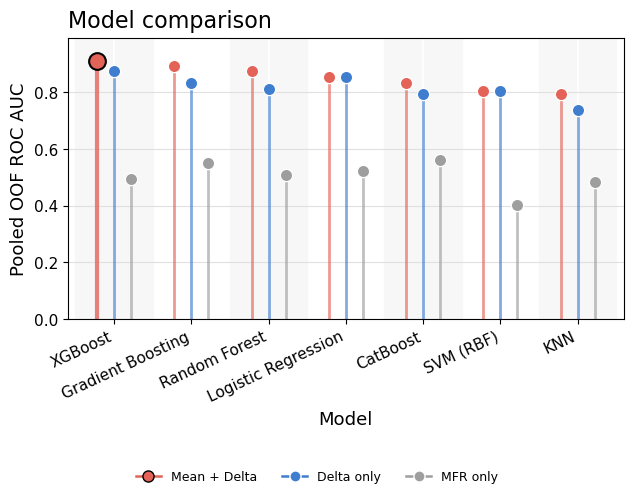

Saved: results/04_performance/figure4/fig4_panelB_model_comparison.png


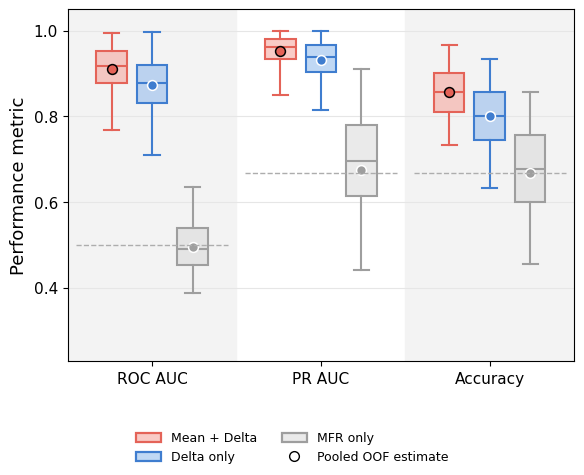

Saved: results/04_performance/figure4/fig4_panelC_selected_model_representation_boxplot.png


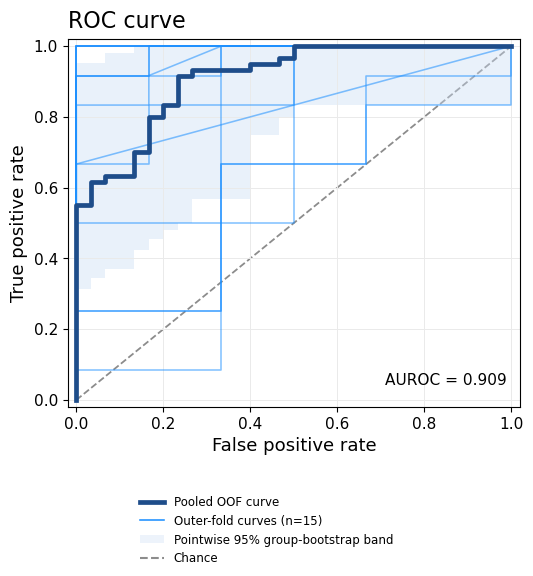

Saved: results/04_performance/figure4/fig4_panelD_roc.png


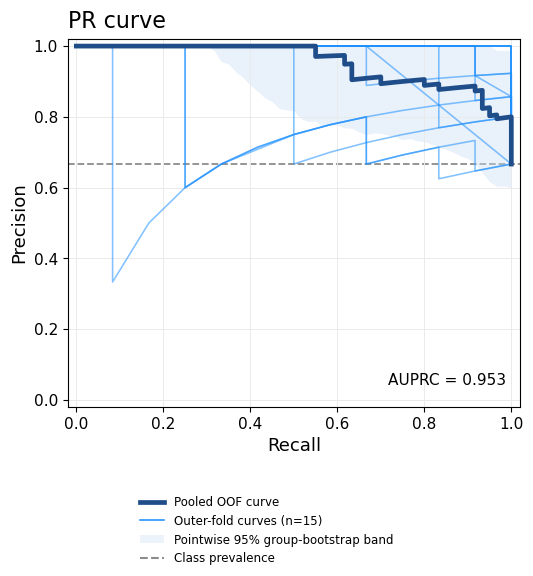

Saved: results/04_performance/figure4/fig4_panelE_pr.png
Saved Figure 4 plots to: results/04_performance/figure4


In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5))
handles = plot_panel_b_model_comparison(ax, main_results_sorted, selected_model, selected_feature_set)
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.tight_layout(rect=[0, 0.09, 1, 1])
save_png(fig, FIG4_OUT_DIR, "fig4_panelB_model_comparison")

fig, ax = plt.subplots(figsize=(6, 4.8))
handles = plot_panel_c_feature_set_comparison(
    ax, selected_model_feature_set_boot_long, selected_model_feature_set_pooled,
    selected_model, selected_feature_set,
)
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=[0, 0.14, 1, 1])
save_png(fig, FIG4_OUT_DIR, "fig4_panelC_selected_model_representation_boxplot")

fig, ax = plt.subplots(figsize=(5.5, 5.8))
handles = plot_panel_d_roc(ax, sel_oof, oof_cols_main, pooled_sel["roc_auc"])
fig.legend(handles=handles, loc="lower center", frameon=False, fontsize=8.5)
fig.tight_layout(rect=[0, 0.17, 1, 1])
save_png(fig, FIG4_OUT_DIR, "fig4_panelD_roc")

fig, ax = plt.subplots(figsize=(5.5, 5.8))
handles = plot_panel_e_pr(ax, sel_oof, oof_cols_main, pooled_sel["pr_auc"])
fig.legend(handles=handles, loc="lower center", frameon=False, fontsize=8.5)
fig.tight_layout(rect=[0, 0.17, 1, 1])
save_png(fig, FIG4_OUT_DIR, "fig4_panelE_pr")

print("Saved Figure 4 plots to:", FIG4_OUT_DIR.relative_to(PROJECT_ROOT))


## Save summary

In [7]:
summary = {
    "training_random_state": RANDOM_STATE,
    "training_protocol_hash": ml_summary.get("training_protocol_hash"),
    "bootstrap_seed": BOOTSTRAP_SEED, "curve_band_seed": CURVE_BAND_SEED,
    "selected_model_name": selected_model,
    "selected_feature_set": selected_feature_set,
    "selected_primary_pooled_metrics": pooled_sel,
    "selected_primary_bootstrap_ci": ci_df.to_dict(orient="records"),
    "selected_model_feature_set_bootstrap_ci": selected_model_feature_set_ci.to_dict(orient="records"),
    "n_oof_rows_selected_primary": int(len(sel_oof)),
    "n_repeats": N_REPEATS,
    "n_outer_folds_per_repeat": OUTER_N_SPLITS,
    "n_outer_fold_curves": len(fold_curve_groups),
    "fold_curve_source": "oof_predictions_by_repeat.csv",
    "pooled_curve_source": "oof_predictions_main.csv (mean probability per well)",
    "curve_band": "pointwise 95% percentile interval; recording-group bootstrap of fixed OOF scores",
    "bootstrap_note": "Conditional on fitted models and the selected combination; model selection and retraining are not repeated.",
    "n_groups_selected_primary": int(sel_oof[oof_cols_main["group_id"]].astype(str).nunique()),
}

with open(FIG4_OUT_DIR / "figure4_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("Saved Figure 4 summary to:", (FIG4_OUT_DIR / "figure4_summary.json").relative_to(PROJECT_ROOT))
print("Selected primary combination:", selected_model, "+", selected_feature_set)
print("Selected primary pooled metrics:")
print(json.dumps(pooled_sel, indent=2))


Saved Figure 4 summary to: results/04_performance/figure4/figure4_summary.json
Selected primary combination: XGBoost + mean+delta
Selected primary pooled metrics:
{
  "roc_auc": 0.9094444444444444,
  "pr_auc": 0.9531639730277037,
  "accuracy": 0.8555555555555555,
  "balanced_accuracy": 0.8166666666666667,
  "f1": 0.896,
  "precision": 0.8615384615384616,
  "recall": 0.9333333333333333,
  "specificity": 0.7
}
